# 01 - Dataset Inspection and Exploratory Data Analysis

Inspect the existing 2015-2024 offshore Udupi wave/wind CSV before agreeing on preprocessing or modeling methodology. Run cells from top to bottom using the project `.venv` kernel in VS Code.

This notebook reads the CSV and displays results inline. It does not change the source file, export datasets/reports, generate ML features or future targets, or train models. All code cells are intentionally unexecuted.

## 1. Load the existing data

Paths are relative to the project. The code supports a kernel working directory of either `notebooks/` or the project root. Timestamps are explicitly parsed as UTC; no source measurements are filled.

In [1]:
from pathlib import Path
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works from notebooks/; the fallback supports a kernel started at the project root.
data_path = Path("../data/udupi_wave_wind_2015_2024.csv")
if not data_path.is_file():
    data_path = Path("data/udupi_wave_wind_2015_2024.csv")
if not data_path.is_file():
    raise FileNotFoundError("Run this notebook from notebooks/ or the project root.")

df = pd.read_csv(data_path, float_precision="round_trip")
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, errors="raise")
print(f"Loaded: {data_path.resolve()}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Loaded: C:\Users\manan_76kj7pv\OneDrive\ML project\Wave Forecasting\data\udupi_wave_wind_2015_2024.csv
Shape: 29,224 rows x 20 columns


,timestamp,latitude,longitude,VHM0,VHM0_SW1,VHM0_SW2,VHM0_WW,VMDR,VMDR_SW1,VMDR_SW2,VMDR_WW,VTM01_SW1,VTM01_SW2,VTM01_WW,VTM02,VTM10,VTPK,eastward_wind,northward_wind,wind_speed
0,2015-01-01 00:00:00+00:00,13.4,74.599998,0.60,0.32,0.23,0.00,245.21,194.34,209.16,213.64,9.12,19.18,0.00,4.46,8.00,19.48,0.363307,0.706901,0.794796
1,2015-01-01 03:00:00+00:00,13.4,74.599998,0.57,0.31,0.26,0.00,239.12,193.46,209.12,145.02,8.96,18.49,0.00,4.66,8.62,19.02,0.563214,0.442098,0.716003
2,2015-01-01 06:00:00+00:00,13.4,74.599998,0.56,0.31,0.27,0.00,235.00,193.34,208.65,216.28,8.86,18.17,0.00,4.81,9.04,19.45,3.602809,0.997492,3.738345
3,2015-01-01 09:00:00+00:00,13.4,74.599998,0.57,0.30,0.29,0.15,233.51,211.54,189.86,249.71,16.71,9.40,1.85,4.29,8.99,19.07,4.851309,0.933394,4.940285
4,2015-01-01 12:00:00+00:00,13.4,74.599998,0.59,0.30,0.29,0.05,233.21,207.88,189.76,276.55,17.15,9.25,1.38,4.28,8.77,18.74,4.215613,-0.653205,4.265920


## 2. Columns, data types and missing values

The timestamp is retained as a column. The expected 20 columns include coordinates, 14 original wave variables, two interpolated wind components and wind speed.

In [2]:
print("Columns:", df.columns.tolist())
column_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100),
})
display(column_summary)

Columns: ['timestamp', 'latitude', 'longitude', 'VHM0', 'VHM0_SW1', 'VHM0_SW2', 'VHM0_WW', 'VMDR', 'VMDR_SW1', 'VMDR_SW2', 'VMDR_WW', 'VTM01_SW1', 'VTM01_SW2', 'VTM01_WW', 'VTM02', 'VTM10', 'VTPK', 'eastward_wind', 'northward_wind', 'wind_speed']


,dtype,missing_count,missing_percent
timestamp,"datetime64[us, UTC]",0,0.0
latitude,float64,0,0.0
longitude,float64,0,0.0
VHM0,float64,0,0.0
VHM0_SW1,float64,0,0.0
VHM0_SW2,float64,0,0.0
VHM0_WW,float64,0,0.0
VMDR,float64,0,0.0
VMDR_SW1,float64,0,0.0
VMDR_SW2,float64,0,0.0


## 3. Timestamp coverage and three-hour continuity

Inspect the original order and duplicates before sorting a separate timestamp series for interval diagnostics. The expected historical grid is fixed to the project's requested coverage, so missing boundary timestamps are also detected. No timestamps are inserted into the measurement data.

In [3]:
timestamps = df["timestamp"]
ordered_times = timestamps.dropna().sort_values()
expected_times = pd.date_range("2015-01-01 00:00", "2024-12-31 21:00", freq="3h", tz="UTC")
actual_times = pd.DatetimeIndex(ordered_times)
missing_times = expected_times.difference(actual_times)
unexpected_times = actual_times.difference(expected_times)
intervals = ordered_times.diff().dropna()

print("Timestamp range:", timestamps.min(), "to", timestamps.max())
print("Timezone:", timestamps.dt.tz)
print("Original order is chronological:", timestamps.is_monotonic_increasing)
print("Inferred frequency:", pd.infer_freq(actual_times) if len(actual_times) >= 3 else "Insufficient timestamps")
print("Duplicate timestamps beyond the first occurrence:", timestamps.duplicated().sum())
print("Missing expected timestamps:", len(missing_times))
print("Unexpected/off-grid timestamps:", len(unexpected_times))
print("Intervals different from 3 hours:", intervals.ne(pd.Timedelta(hours=3)).sum())
display(intervals.value_counts().rename_axis("interval").to_frame("count"))
if len(missing_times):
    display(pd.DataFrame({"missing_timestamp": missing_times}))
if len(unexpected_times):
    display(pd.DataFrame({"unexpected_timestamp": unexpected_times}))
if timestamps.duplicated(keep=False).any():
    display(df.loc[timestamps.duplicated(keep=False)])

Timestamp range: 2015-01-01 00:00:00+00:00 to 2024-12-31 21:00:00+00:00
Timezone: UTC
Original order is chronological: True
Inferred frequency: 3h
Duplicate timestamps beyond the first occurrence: 0
Missing expected timestamps: 0
Unexpected/off-grid timestamps: 0
Intervals different from 3 hours: 0


,count
interval,
0 days 03:00:00,29223


## 4. Numerical descriptive statistics

Inspect every numeric column, including coordinates. Standard deviations use the Pandas sample definition. Infinite values are counted separately from missing values; this inspection does not correct either.

In [4]:
numerical = df.select_dtypes(include="number")
statistics = numerical.describe(percentiles=[0.50, 0.90, 0.95, 0.99]).T
statistics = statistics.rename(columns={"50%": "median", "90%": "p90", "95%": "p95", "99%": "p99"})
statistics["missing_count"] = numerical.isna().sum()
statistics["infinite_count"] = np.isinf(numerical).sum()
display(statistics)

,count,mean,std,min,median,p90,p95,p99,max,missing_count,infinite_count
latitude,29224.0,13.400000,0.000000,13.400000,13.400000,13.400000,13.400000,13.400000,13.400000,0,0
longitude,29224.0,74.599998,0.000000,74.599998,74.599998,74.599998,74.599998,74.599998,74.599998,0,0
VHM0,29224.0,1.085376,0.733159,0.290000,0.740000,2.240000,2.670000,3.290000,5.000000,0,0
VHM0_SW1,29224.0,0.922174,0.756820,0.150000,0.540000,2.160000,2.560000,3.150000,4.410000,0,0
VHM0_SW2,29224.0,0.336269,0.137192,0.000000,0.320000,0.500000,0.570000,0.780000,1.950000,0,0
VHM0_WW,29224.0,0.121426,0.208530,0.000000,0.030000,0.360000,0.520000,0.950000,3.320000,0,0
VMDR,29224.0,245.099481,27.398835,58.480000,251.220000,276.044000,288.738500,301.010000,357.650000,0,0
VMDR_SW1,29224.0,241.654749,43.974302,170.770000,255.360000,308.260000,311.980000,316.770000,323.840000,0,0
VMDR_SW2,29224.0,203.860117,37.479458,76.250000,201.665000,254.672000,309.400000,318.687700,354.670000,0,0
VMDR_WW,29224.0,229.834680,100.824725,0.020000,265.030000,332.840000,344.650000,356.127700,359.990000,0,0


## 5. Significant wave-height distribution and provisional ranges

`VHM0` is total significant wave height in metres. The counts below describe **current observed/modelled heights**, not the six-hour future target or its class balance. Missing heights are reported separately and excluded from the percentage denominator.

The 2.5 m and 3.0 m boundaries are provisional research thresholds, not official marine warnings. This notebook does not construct labels or future maxima.

,VHM0 (m)
count,29224.000000
mean,1.085376
std,0.733159
min,0.290000
50%,0.740000
90%,2.240000
95%,2.670000
99%,3.290000
max,5.000000


,count,percent_of_nonmissing_heights
Below 2.5 m,27245,93.228169
2.5-3.0 m inclusive,1268,4.338900
Above 3.0 m,711,2.432932


Missing VHM0 measurements: 0


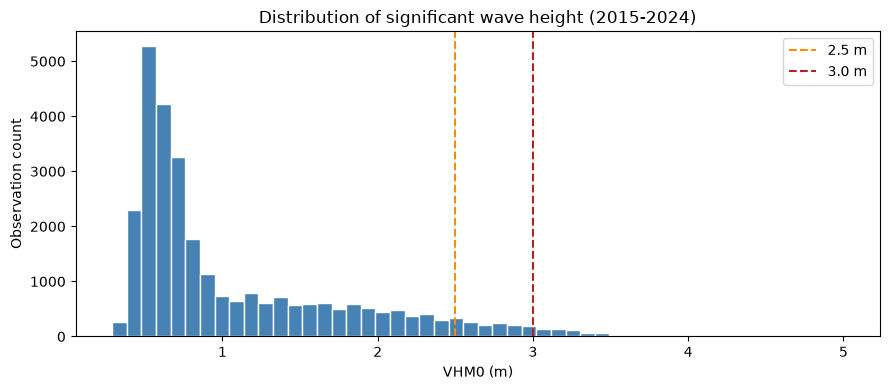

In [5]:
wave = df["VHM0"]
valid_wave = wave.dropna()
if valid_wave.empty:
    raise ValueError("VHM0 has no valid observations to summarize.")
display(valid_wave.describe(percentiles=[0.50, 0.90, 0.95, 0.99]).to_frame("VHM0 (m)"))

range_counts = pd.Series({
    "Below 2.5 m": valid_wave.lt(2.5).sum(),
    "2.5-3.0 m inclusive": valid_wave.between(2.5, 3.0, inclusive="both").sum(),
    "Above 3.0 m": valid_wave.gt(3.0).sum(),
}, name="count")
range_summary = range_counts.to_frame()
range_summary["percent_of_nonmissing_heights"] = range_counts.div(len(valid_wave)).mul(100)
display(range_summary)
print("Missing VHM0 measurements:", wave.isna().sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(valid_wave, bins=50, color="steelblue", edgecolor="white")
ax.axvline(2.5, color="darkorange", linestyle="--", label="2.5 m")
ax.axvline(3.0, color="firebrick", linestyle="--", label="3.0 m")
ax.set(title="Distribution of significant wave height (2015-2024)", xlabel="VHM0 (m)", ylabel="Observation count")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Monthly and yearly patterns

Monthly summaries pool the same calendar month across all ten years. Exceedance percentages use nonmissing heights in each month; "above" is strictly greater than each threshold. These tables and plots are exploratory summaries, not engineered predictor columns.

,count,min,max,mean,median,std,percent_above_2.5m,percent_above_3.0m
month,,,,,,,,
1,2480,0.29,1.36,0.598887,0.56,0.165072,0.000000,0.000000
2,2264,0.38,1.65,0.625057,0.61,0.154580,0.000000,0.000000
3,2480,0.40,2.01,0.644581,0.62,0.144219,0.000000,0.000000
4,2400,0.41,2.19,0.654450,0.63,0.133623,0.000000,0.000000
5,2480,0.46,5.00,0.976911,0.83,0.465910,1.129032,0.725806
6,2400,0.66,4.23,2.016996,1.96,0.677150,23.458333,9.375000
7,2480,1.12,3.91,2.382621,2.34,0.556482,40.685484,13.387097
8,2480,0.82,4.22,1.878919,1.81,0.556854,12.016129,5.080645
9,2400,0.57,2.88,1.297187,1.23,0.404535,0.875000,0.000000


,count,min,max,mean,median,std
timestamp,,,,,,
2015,2920,0.40,4.23,1.016438,0.74,0.654282
2016,2928,0.33,3.58,1.130003,0.77,0.727471
2017,2920,0.36,3.25,1.097363,0.76,0.682468
2018,2920,0.29,3.87,1.114493,0.68,0.847984
2019,2920,0.37,3.56,1.125921,0.76,0.760439
2020,2928,0.32,4.22,1.096284,0.74,0.723863
2021,2920,0.35,5.00,1.116205,0.76,0.747195
2022,2920,0.34,3.90,1.070168,0.74,0.745467
2023,2920,0.31,3.91,0.991969,0.67,0.688382


Months ranked by proportion above 2.5 m:


,count,percent_above_2.5m,percent_above_3.0m
month,,,
7,2480,40.685484,13.387097
6,2400,23.458333,9.375000
8,2480,12.016129,5.080645
5,2480,1.129032,0.725806
10,2480,0.927419,0.403226
9,2400,0.875000,0.000000
2,2264,0.000000,0.000000
1,2480,0.000000,0.000000
4,2400,0.000000,0.000000


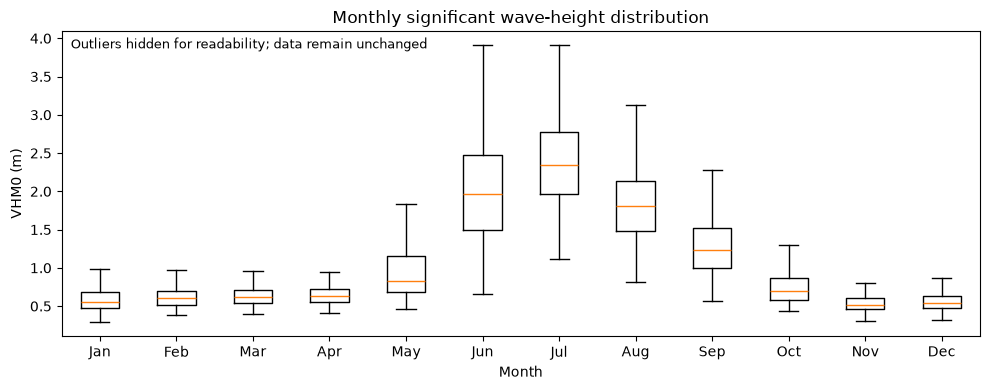

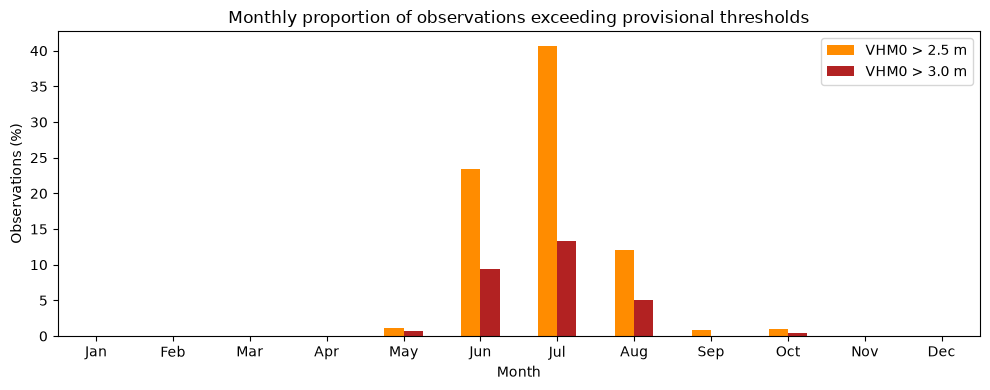

In [6]:
monthly_groups = wave.groupby(df["timestamp"].dt.month)
monthly = monthly_groups.agg(["count", "min", "max", "mean", "median", "std"])
monthly["percent_above_2.5m"] = monthly_groups.apply(lambda values: values.dropna().gt(2.5).mean() * 100)
monthly["percent_above_3.0m"] = monthly_groups.apply(lambda values: values.dropna().gt(3.0).mean() * 100)
monthly.index.name = "month"
display(monthly)
display(wave.groupby(df["timestamp"].dt.year).agg(["count", "min", "max", "mean", "median", "std"]))
print("Months ranked by proportion above 2.5 m:")
display(monthly[["count", "percent_above_2.5m", "percent_above_3.0m"]].sort_values("percent_above_2.5m", ascending=False))

month_numbers = list(range(1, 13))
month_labels = [calendar.month_abbr[month] for month in month_numbers]
fig, ax = plt.subplots(figsize=(10, 4))
monthly_samples = [wave.loc[df["timestamp"].dt.month.eq(month)].dropna().to_numpy() for month in month_numbers]
ax.boxplot(monthly_samples, showfliers=False)
ax.set_xticks(month_numbers, month_labels)
ax.set(title="Monthly significant wave-height distribution", xlabel="Month", ylabel="VHM0 (m)")
ax.text(0.01, 0.98, "Outliers hidden for readability; data remain unchanged", transform=ax.transAxes, va="top", fontsize=9)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
monthly[["percent_above_2.5m", "percent_above_3.0m"]].rename(columns={
    "percent_above_2.5m": "VHM0 > 2.5 m", "percent_above_3.0m": "VHM0 > 3.0 m"
}).plot.bar(ax=ax, color=["darkorange", "firebrick"])
ax.set_xticklabels([calendar.month_abbr[int(month)] for month in monthly.index], rotation=0)
ax.set(title="Monthly proportion of observations exceeding provisional thresholds", xlabel="Month", ylabel="Observations (%)")
fig.tight_layout()
plt.show()

## 7. Discussion before preprocessing

After running the cells, discuss the frequency of elevated/high-wave observations, monthly concentration, any data-quality issues and the suitability of provisional thresholds. Adjacent three-hour observations are temporally dependent; observation counts are not independent event counts.

Full-period EDA is descriptive. Before model development, agree on a chronological holdout and avoid using its outcomes to tune thresholds, features or models. No preprocessing, feature generation, future targets or training is implemented here. Record conclusions only after inspecting the outputs; none are assumed in advance.